In [7]:
from google.colab import files
uploaded = files.upload()


Saving major project.csv to major project (1).csv


In [8]:
import pandas as pd

df = pd.read_csv('major project.csv', encoding='utf-8')
print(df.head())


  Show_Id Category  Title           Director  \
0      s1  TV Show     3%                NaN   
1      s2    Movie  07:19  Jorge Michel Grau   
2      s3    Movie  23:59       Gilbert Chan   
3      s4    Movie      9        Shane Acker   
4      s5    Movie     21     Robert Luketic   

                                                Cast        Country  \
0  João Miguel, Bianca Comparato, Michel Gomes, R...         Brazil   
1  Demián Bichir, Héctor Bonilla, Oscar Serrano, ...         Mexico   
2  Tedd Chan, Stella Chung, Henley Hii, Lawrence ...      Singapore   
3  Elijah Wood, John C. Reilly, Jennifer Connelly...  United States   
4  Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...  United States   

        Release_Date Rating   Duration  \
0    August 14, 2020  TV-MA  4 Seasons   
1  December 23, 2016  TV-MA     93 min   
2  December 20, 2018      R     78 min   
3  November 16, 2017  PG-13     80 min   
4    January 1, 2020  PG-13    123 min   

                               

In [9]:
# === Cell 1: Import Required Libraries ===

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, roc_auc_score, confusion_matrix
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

sns.set(style="whitegrid")


In [10]:
# === Cell 2: Load Dataset ===

# Upload the file manually or mount Google Drive before this cell if using Drive.
# Example: from google.colab import drive; drive.mount('/content/drive')

try:
    df
except NameError:
    df = pd.read_csv('major project.csv', encoding='utf-8')

# Clean column names
df.columns = [c.strip().replace(' ', '_') for c in df.columns]

# Convert Release_Date column to datetime if available
if 'Release_Date' in df.columns:
    df['Release_Date'] = pd.to_datetime(df['Release_Date'], errors='coerce')

print("Dataset shape:", df.shape)
df.head()


Dataset shape: (7789, 11)


,Show_Id,Category,Title,Director,Cast,Country,Release_Date,Rating,Duration,Type,Description
0,s1,TV Show,3%,NaN,"João Miguel, Bianca Comparato, Michel Gomes, R...",Brazil,2020-08-14,TV-MA,4 Seasons,"International TV Shows, TV Dramas, TV Sci-Fi &...",In a future where the elite inhabit an island ...
1,s2,Movie,07:19,Jorge Michel Grau,"Demián Bichir, Héctor Bonilla, Oscar Serrano, ...",Mexico,2016-12-23,TV-MA,93 min,"Dramas, International Movies",After a devastating earthquake hits Mexico Cit...
2,s3,Movie,23:59,Gilbert Chan,"Tedd Chan, Stella Chung, Henley Hii, Lawrence ...",Singapore,2018-12-20,R,78 min,"Horror Movies, International Movies","When an army recruit is found dead, his fellow..."
3,s4,Movie,9,Shane Acker,"Elijah Wood, John C. Reilly, Jennifer Connelly...",United States,2017-11-16,PG-13,80 min,"Action & Adventure, Independent Movies, Sci-Fi...","In a postapocalyptic world, rag-doll robots hi..."
4,s5,Movie,21,Robert Luketic,"Jim Sturgess, Kevin Spacey, Kate Bosworth, Aar...",United States,2020-01-01,PG-13,123 min,Dramas,A brilliant group of students become card-coun...


In [11]:
# === Cell 3: Build Genres_Text Column ===

if 'Type' in df.columns and 'Category' in df.columns:
    df['Genres_Text'] = df['Type'].astype(str)
else:
    df['Genres_Text'] = df.get('Description', pd.Series(index=df.index, dtype='object')).astype(str)

print(df['Genres_Text'].head())


0    International TV Shows, TV Dramas, TV Sci-Fi &...
1                         Dramas, International Movies
2                  Horror Movies, International Movies
3    Action & Adventure, Independent Movies, Sci-Fi...
4                                               Dramas
Name: Genres_Text, dtype: object


In [12]:
# === Cell 4: Genre Imputation Using Keywords ===

text_src = (df['Title'].fillna('') + ' ' + df['Description'].fillna('')).str.lower()

keyword_map = {
    'Horror': ['horror', 'haunted', 'ghost', 'zombie', 'possession', 'slasher', 'terrifying'],
    'Comedy': ['comedy', 'funny', 'humor', 'hilarious', 'sitcom'],
    'Drama': ['drama', 'dramatic', 'emotional', 'biopic'],
    'Action & Adventure': ['action', 'adventure', 'spy', 'espionage', 'fight', 'battle', 'chase'],
    'Sci-Fi & Fantasy': ['sci-fi', 'science fiction', 'fantasy', 'space', 'alien', 'time travel', 'supernatural'],
    'Romance': ['romance', 'romantic', 'love story', 'love'],
    'Thriller': ['thriller', 'suspense', 'mystery', 'crime'],
    'Documentaries': ['documentary', 'docuseries', 'true story', 'biography'],
    'Kids & Family': ['kids', 'family', 'animated', 'animation', 'cartoon', 'children'],
    'International Movies': ['international', 'foreign'],
}

def split_genres(s):
    if pd.isna(s): return []
    return [p.strip() for p in str(s).split(',') if p.strip() != '']

existing_genres = df['Genres_Text'].apply(split_genres)
has_genres_mask = existing_genres.apply(lambda lst: len(lst) > 0)

imputed_genres = []
for i, txt in enumerate(text_src):
    if has_genres_mask.iat[i]:
        imputed_genres.append(existing_genres.iat[i])
        continue
    found = []
    for g, kws in keyword_map.items():
        for kw in kws:
            if kw in txt:
                found.append(g)
                break
    if not found:
        found = ['Misc']
    imputed_genres.append(sorted(list(set(found))))

df['Genre_List'] = imputed_genres
print("✅ Genres imputed successfully")


✅ Genres imputed successfully


In [13]:
# === Cell 5: Country lists, target, and numeric features ===

df['Country_List'] = df['Country'].fillna('').astype(str).str.split(',').apply(lambda xs: [x.strip() for x in xs if x.strip()])

# Target: Movie vs TV Show
if 'Category' in df.columns:
    df['y'] = df['Category'].astype(str).str.contains('TV Show', case=False).map({True: 'TV Show', False: 'Movie'})
else:
    df['y'] = df['Duration'].astype(str).str.contains('Season').map({True: 'TV Show', False: 'Movie'})

def parse_duration(val):
    if pd.isna(val): return np.nan
    s = str(val)
    if 'Season' in s:
        try: return int(s.split(' ')[0]) * 60
        except: return np.nan
    if 'min' in s:
        try: return int(s.split(' ')[0])
        except: return np.nan
    try: return int(s)
    except: return np.nan

df['duration_num'] = df['Duration'].apply(parse_duration)
df['year_added'] = df['Release_Date'].dt.year
df['cast_len'] = df['Cast'].astype(str).apply(lambda x: len([p for p in x.split(',') if p.strip()]))
df['desc_len'] = df['Description'].astype(str).apply(len)

print("✅ Feature columns created")


✅ Feature columns created


In [14]:
# === Cell 6: One-hot encoding for genres and countries ===

# Top genres
all_genres_flat = [g for lst in df['Genre_List'] for g in lst]
top_genres = pd.Series(all_genres_flat).value_counts().head(12).index.tolist()

for g in top_genres:
    df['genre_' + g.replace(' ', '_').replace('&', 'and')] = df['Genre_List'].apply(lambda lst: g in lst)

# Top countries
all_countries_flat = [c for lst in df['Country_List'] for c in lst]
top_countries = pd.Series(all_countries_flat).value_counts().head(12).index.tolist()

for c in top_countries:
    df['country_' + c.replace(' ', '_')] = df['Country_List'].apply(lambda lst: c in lst)

print("✅ One-hot encoded top genres and countries")


✅ One-hot encoded top genres and countries


In [15]:
# === Cell 7: Train/Test Split and Model Training ===

num_features = ['duration_num','year_added','cast_len','desc_len']
cat_features = ['Rating']
extra_bool = [c for c in df.columns if c.startswith('genre_') or c.startswith('country_')]

X = df[num_features + cat_features + extra_bool].copy()
y = df['y']

# Handle missing numeric values
for c in num_features:
    X[c] = pd.to_numeric(X[c], errors='coerce')
X[num_features] = X[num_features].fillna(X[num_features].median())

# Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

# Pipelines
preprocess = ColumnTransformer(
    transformers=[('cat', OneHotEncoder(handle_unknown='ignore'), cat_features)],
    remainder='passthrough'
)

log_clf = Pipeline(steps=[('pre', preprocess), ('clf', LogisticRegression(max_iter=400))])
rf_clf = Pipeline(steps=[('pre', preprocess), ('clf', RandomForestClassifier(n_estimators=400, random_state=42))])

log_clf.fit(X_train, y_train)
rf_clf.fit(X_train, y_train)

log_pred = log_clf.predict(X_test)
rf_pred = rf_clf.predict(X_test)
log_proba = log_clf.predict_proba(X_test)[:,1]

print("Logistic Regression Report:\n", classification_report(y_test, log_pred))
print("Random Forest Report:\n", classification_report(y_test, rf_pred))

try:
    auc_log = roc_auc_score((y_test=='TV Show').astype(int), log_proba)
    print("LogReg ROC-AUC:", auc_log)
except Exception:
    print("AUC calculation failed")


/usr/local/lib/python3.12/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression Report:
               precision    recall  f1-score   support

       Movie       0.97      0.99      0.98      1345
     TV Show       0.97      0.94      0.95       603

    accuracy                           0.97      1948
   macro avg       0.97      0.96      0.97      1948
weighted avg       0.97      0.97      0.97      1948

Random Forest Report:
               precision    recall  f1-score   support

       Movie       1.00      1.00      1.00      1345
     TV Show       0.99      1.00      1.00       603

    accuracy                           1.00      1948
   macro avg       1.00      1.00      1.00      1948
weighted avg       1.00      1.00      1.00      1948

LogReg ROC-AUC: 0.9963084207216704


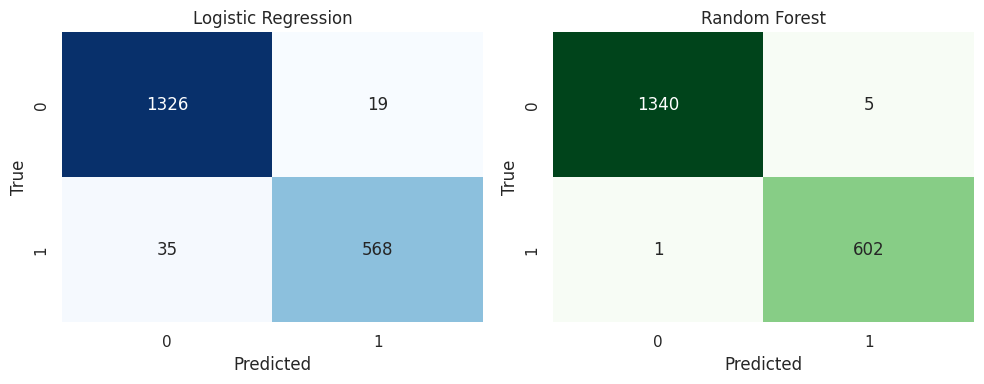

In [16]:
# === Cell 8: Confusion Matrices Visualization ===

fig, axes = plt.subplots(1,2, figsize=(10,4))
cm_log = confusion_matrix(y_test, log_pred, labels=['Movie','TV Show'])
cm_rf = confusion_matrix(y_test, rf_pred, labels=['Movie','TV Show'])

sns.heatmap(cm_log, annot=True, fmt='d', cmap='Blues', cbar=False, ax=axes[0])
axes[0].set_title('Logistic Regression')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('True')

sns.heatmap(cm_rf, annot=True, fmt='d', cmap='Greens', cbar=False, ax=axes[1])
axes[1].set_title('Random Forest')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('True')

plt.tight_layout()
plt.show()


/tmp/ipython-input-919659772.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=imp_series.values, y=imp_series.index, palette='rocket')


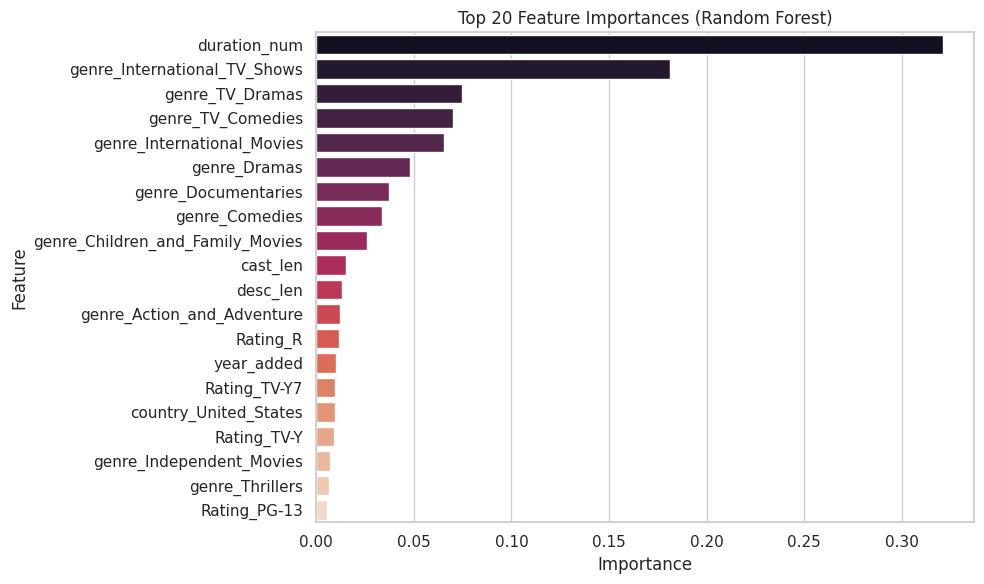

In [17]:
# === Cell 9: Feature Importance ===

ohe = rf_clf.named_steps['pre'].named_transformers_['cat']
ohe_features = list(ohe.get_feature_names_out(cat_features))
other_features = [f for f in X.columns if f not in cat_features]
feat_names = ohe_features + other_features

importances = rf_clf.named_steps['clf'].feature_importances_
imp_series = pd.Series(importances, index=feat_names).sort_values(ascending=False).head(20)

plt.figure(figsize=(10,6))
sns.barplot(x=imp_series.values, y=imp_series.index, palette='rocket')
plt.title('Top 20 Feature Importances (Random Forest)')
plt.xlabel('Importance')
plt.ylabel('Feature')
plt.tight_layout()
plt.show()


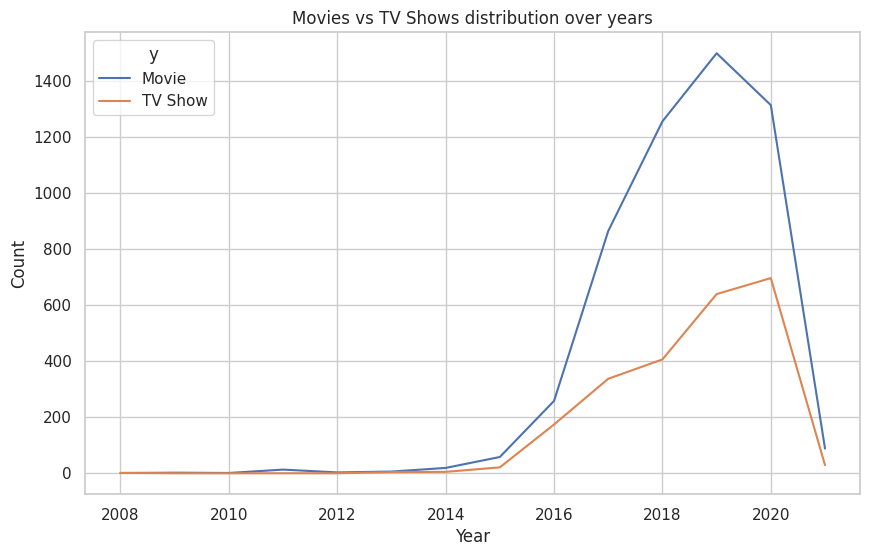

In [19]:
df['year'] = df['Release_Date'].dt.year
yearly_counts = df.groupby(['year', 'y']).size().unstack(fill_value=0)
yearly_counts.plot(kind='line', figsize=(10,6))
plt.title('Movies vs TV Shows distribution over years')
plt.xlabel('Year')
plt.ylabel('Count')
plt.grid(True)
plt.show()


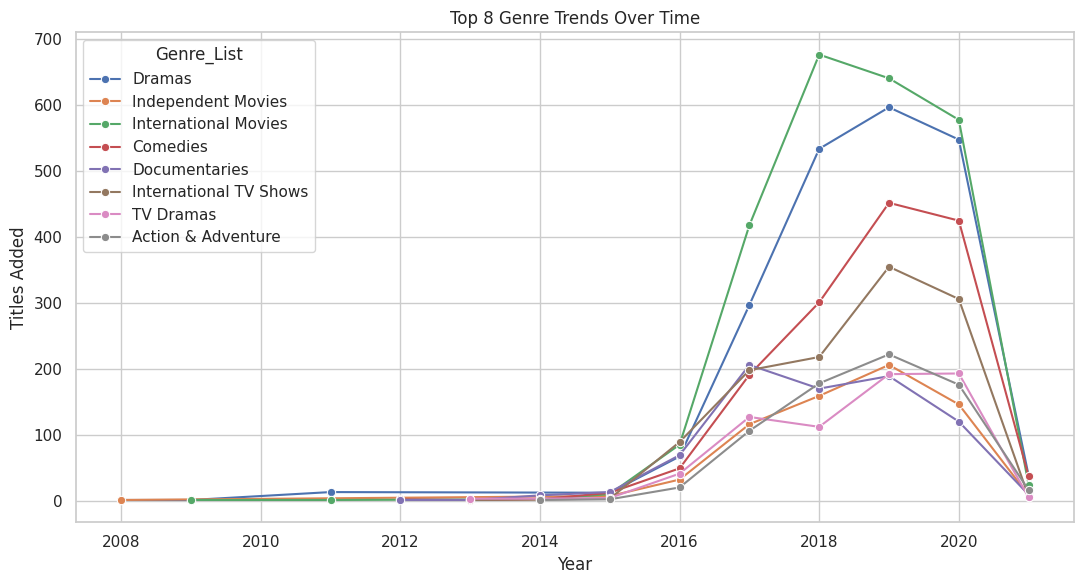

/tmp/ipython-input-2547731758.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=country_ct.values, y=country_ct.index, orient='h', palette='mako')


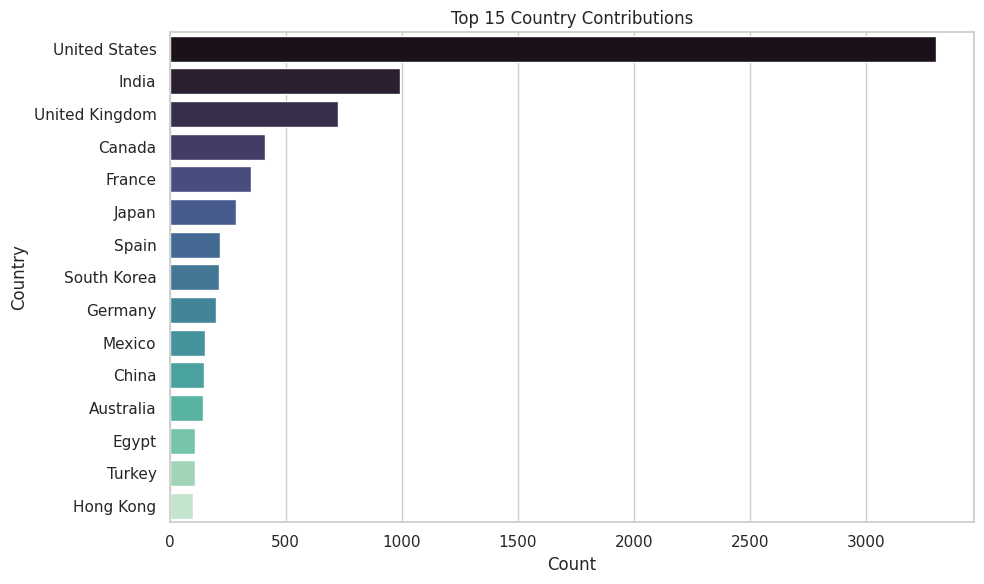

✅ Completed genre imputation, feature engineering, model training, and visualization


In [18]:
# === Cell 10: Genre and Country Visualizations ===

# Genre trends over time
plot_df = df[['Release_Date','Genre_List']].dropna(subset=['Release_Date']).copy()
plot_df['year'] = plot_df['Release_Date'].dt.year
plot_df = plot_df.explode('Genre_List')

top8 = plot_df['Genre_List'].value_counts().head(8).index.tolist()
trend = plot_df[plot_df['Genre_List'].isin(top8)].groupby(['year','Genre_List']).size().reset_index(name='count')

plt.figure(figsize=(11,6))
sns.lineplot(data=trend, x='year', y='count', hue='Genre_List', marker='o')
plt.title('Top 8 Genre Trends Over Time')
plt.xlabel('Year')
plt.ylabel('Titles Added')
plt.tight_layout()
plt.show()

# Country contributions
country_plot = df.explode('Country_List')
country_ct = country_plot['Country_List'].value_counts().head(15)

plt.figure(figsize=(10,6))
sns.barplot(x=country_ct.values, y=country_ct.index, orient='h', palette='mako')
plt.title('Top 15 Country Contributions')
plt.xlabel('Count')
plt.ylabel('Country')
plt.tight_layout()
plt.show()

print("✅ Completed genre imputation, feature engineering, model training, and visualization")
